<a href="https://colab.research.google.com/github/Sanctusofficial/Sanctusofficial/blob/main/Datasets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install librosa scikit-learn matplotlib seaborn numpy requests -q

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import os
import requests
import zipfile
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score)

print("Ready.")

Ready.


In [ ]:
# Download the dataset directly from Zenodo (official source)
url = "https://zenodo.org/record/1203745/files/UrbanSound8K.tar.gz"

print("Downloading UrbanSound8K... this may take 5-10 minutes.")
!wget -q --show-progress -O UrbanSound8K.tar.gz "{url}"
!tar -xzf UrbanSound8K.tar.gz
print("Done.")

UrbanSound8K.tar.gz 100%[===================>]   5.61G  16.7MB/s    in 5m 38s  
Done.


In [ ]:
# UrbanSound8K has 10 classes. We map them to our 5 categories.
# Class IDs: 0=AC, 1=car_horn, 2=children, 3=dog_bark,
#             4=drilling, 5=engine_idling, 6=gun_shot,
#             7=jackhammer, 8=siren, 9=street_music

CLASS_MAP = {
    0: "Mechanical",   # air conditioner
    1: "Transient",    # car horn
    2: "Speech",       # children playing
    3: "Transient",    # dog bark
    4: "Mechanical",   # drilling
    5: "Mechanical",   # engine idling
    6: "Transient",    # gun shot
    7: "Mechanical",   # jackhammer
    8: "Transient",    # siren
    9: "Crowd",        # street music
}

LABEL_NAMES = ["Crowd", "Mechanical", "Speech", "Transient"]

def extract_features(file_path):
    try:
        y, sr = librosa.load(file_path, sr=22050, duration=3.0, mono=True)
        if len(y) < sr * 0.5:
            return None
        mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=40, n_fft=1024, window='hann')
        mel_db = librosa.power_to_db(mel, ref=np.max)
        features = np.concatenate([
            np.mean(mel_db, axis=1),
            np.std(mel_db, axis=1)
        ])
        return features
    except Exception:
        return None

# Collect features from folds 1-8 (train), fold 9-10 (test)
print("Extracting features from real audio files...")
print("This will take 3-5 minutes...")

X_train, y_train = [], []
X_test,  y_test  = [], []

audio_dir = "UrbanSound8K/audio"

for fold in range(1, 11):
    fold_path = os.path.join(audio_dir, f"fold{fold}")
    if not os.path.exists(fold_path):
        continue
    files = os.listdir(fold_path)
    for fname in files:
        if not fname.endswith('.wav'):
            continue
        class_id = int(fname.split('-')[1])
        label = CLASS_MAP.get(class_id)
        if label is None:
            continue
        fpath = os.path.join(fold_path, fname)
        feats = extract_features(fpath)
        if feats is None:
            continue
        if fold <= 8:
            X_train.append(feats)
            y_train.append(label)
        else:
            X_test.append(feats)
            y_test.append(label)

X_train = np.array(X_train)
X_test  = np.array(X_test)

print(f"Training samples: {len(X_train)}")
print(f"Test samples:     {len(X_test)}")
print(f"Classes: {set(y_train)}")

Extracting features from real audio files...
This will take 3-5 minutes...
Training samples: 6937
Test samples:     1629
Classes: {'Crowd', 'Speech', 'Transient', 'Mechanical'}


In [ ]:
clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"\nOverall Accuracy: {acc*100:.1f}%")
print()
print(classification_report(y_test, y_pred))

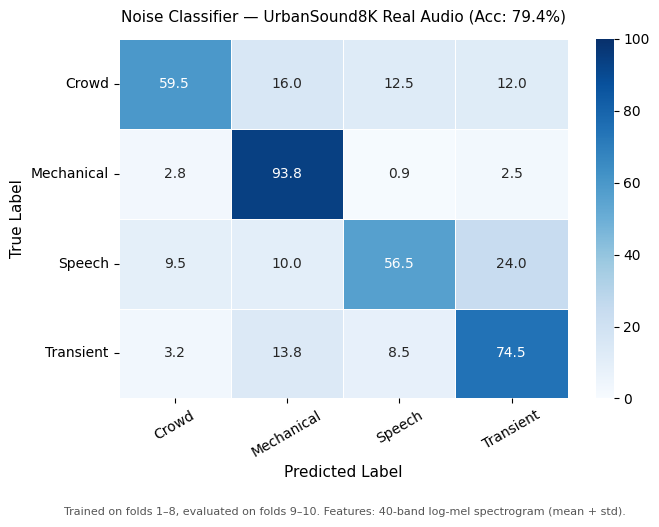

Saved. Accuracy: 79.4%


In [ ]:
labels = sorted(list(set(y_test)))
cm = confusion_matrix(y_test, y_pred, labels=labels)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm_norm, annot=True, fmt='.1f',
            xticklabels=labels, yticklabels=labels,
            cmap='Blues', vmin=0, vmax=100,
            linewidths=0.5, linecolor='white', ax=ax)
ax.set_xlabel('Predicted Label', fontsize=11)
ax.set_ylabel('True Label', fontsize=11)
ax.set_title(
    f'Noise Classifier — UrbanSound8K Real Audio (Acc: {acc*100:.1f}%)',
    fontsize=11, pad=12)
ax.tick_params(axis='x', rotation=30)
ax.tick_params(axis='y', rotation=0)
fig.text(0.5, -0.04,
    'Trained on folds 1–8, evaluated on folds 9–10. '
    'Features: 40-band log-mel spectrogram (mean + std).',
    ha='center', fontsize=8, color='#555555')
plt.tight_layout()
plt.savefig('confusion_matrix_real.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved. Accuracy: {acc*100:.1f}%")